<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB
None
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


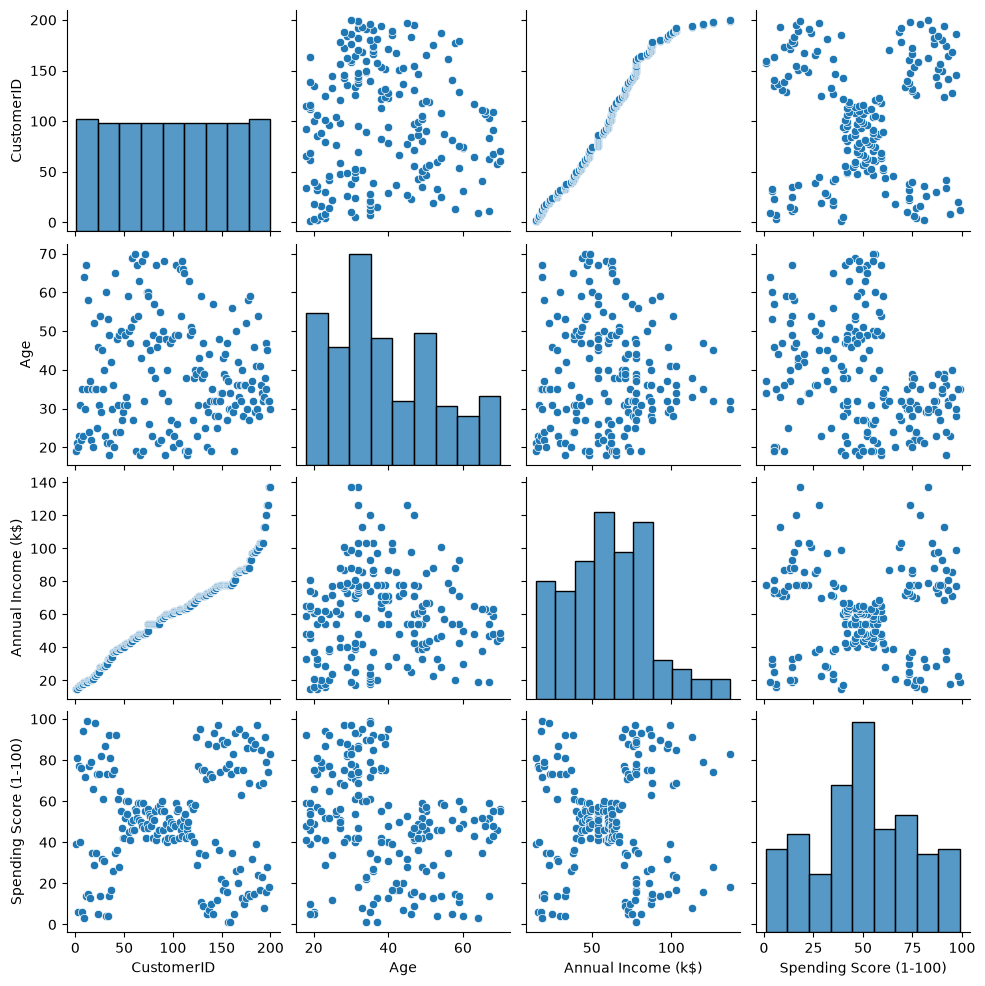

   Annual Income (k$)  Spending Score (1-100)  label
0                  15                      39      4
1                  15                      81      2
2                  16                       6      4
3                  16                      77      2
4                  17                      40      4


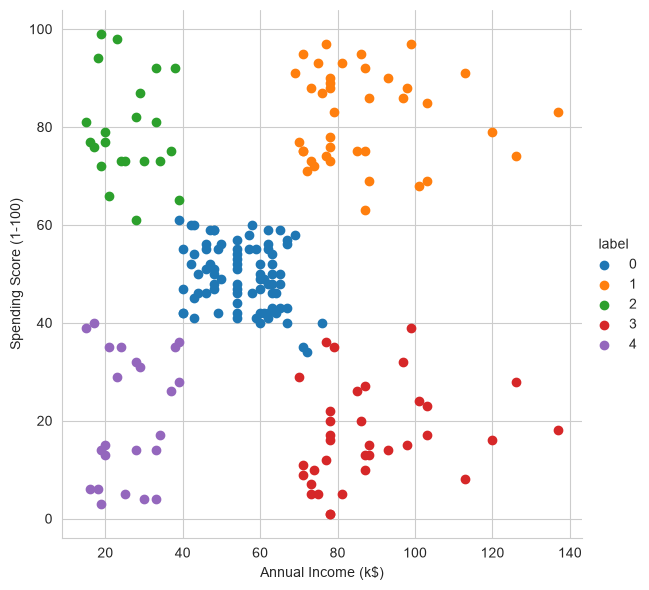

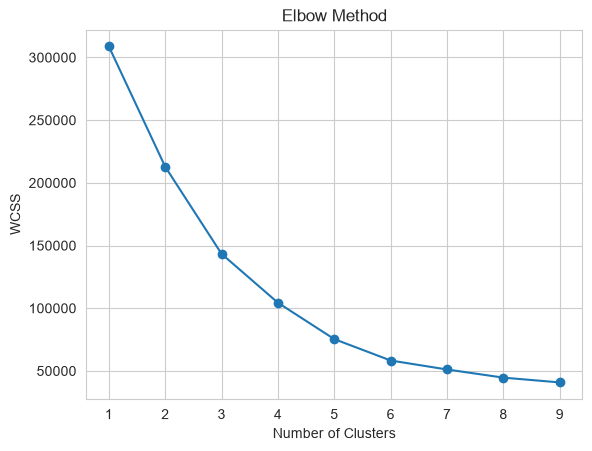

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\Hp\Desktop\Mall_Customers_converted.csv")

print(df.info())
print(df.head())

sns.pairplot(df)
plt.show()

features = df.iloc[:, [3, 4]].values

from sklearn.cluster import KMeans

model = KMeans(n_clusters=5, random_state=42, n_init=10)
model.fit(features)

Final = df.iloc[:, [3, 4]].copy()
Final['label'] = model.predict(features)

print(Final.head())

sns.set_style("whitegrid")

sns.FacetGrid(Final, hue="label", height=6) \
    .map(plt.scatter, "Annual Income (k$)",
         "Spending Score (1-100)") \
    .add_legend()

plt.show()

features_el = df.iloc[:, [2, 3, 4]].values

wcss = []

for i in range(1, 10):
    model_elbow = KMeans(
        n_clusters=i, random_state=42, n_init=10
    )
    model_elbow.fit(features_el)
    wcss.append(model_elbow.inertia_)

plt.plot(range(1, 10), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()